In [1]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Input values
X = np.array([[2, 3]])

# Weights
W = np.array([[0.5], [0.2]])

# Bias
b = 0.1

# Weighted sum
z = X @ W + b

# Neuron output
output = sigmoid(z)

print("Weighted sum:", z)
print("Neuron output:", output)

Weighted sum: [[1.7]]
Neuron output: [[0.84553473]]


In [2]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Two inputs
X = np.array([[2, 3]])

# Weights for 3 hidden neurons
W1 = np.array([
    [0.5, 0.2, 0.8],
    [0.2, 0.4, 0.1]
])

# One bias for each neuron
b1 = np.array([[0.1, 0.2, 0.3]])

# Hidden layer calculation
Z1 = X @ W1 + b1
H = sigmoid(Z1)

print("Weighted sums:", Z1)
print("Hidden layer outputs:", H)
print("Output shape:", H.shape)

Weighted sums: [[1.7 1.8 2.2]]
Hidden layer outputs: [[0.84553473 0.85814894 0.90024951]]
Output shape: (1, 3)


In [3]:
# Weights connecting 3 hidden neurons to 1 output neuron
W2 = np.array([[0.4], [0.6], [0.3]])

b2 = np.array([[0.1]])

# Output layer
Z2 = H @ W2 + b2
output = sigmoid(Z2)

print("Output weighted sum:", Z2)
print("Final network output:", output)

Output weighted sum: [[1.22317811]]
Final network output: [[0.77262235]]


In [4]:
y = np.array([[1]]) # Actual answer

loss = np.mean((output - y) ** 2) # Mean Squared Error

print("Prediction:", output)
print("Actual:", y)
print("Loss:", loss)

Prediction: [[0.77262235]]
Actual: [[1]]
Loss: 0.05170059398524644


In [5]:
# output layer gradient
dZ2 = 2 * (output - y) * output * (1 - output)

print("Output layer gradient:", dZ2)

Output layer gradient: [[-0.07989007]]


In [6]:
# Gradients for output layer weights and bias
dW2 = H.T @ dZ2
db2 = np.sum(dZ2, axis=0, keepdims=True)

print("Gradient of W2:\n", dW2)
print("Gradient of b2:\n", db2)

Gradient of W2:
 [[-0.06754983]
 [-0.06855758]
 [-0.071921  ]]
Gradient of b2:
 [[-0.07989007]]


In [7]:
# Calculate hidden layer gradients
dZ1 = (dZ2 @ W2.T) * H * (1 - H)

print("Hidden layer gradients:\n", dZ1)
print("Gradient shape:", dZ1.shape)

Hidden layer gradients:
 [[-0.00417364 -0.00583498 -0.00215225]]
Gradient shape: (1, 3)


In [8]:
# Gradients for hidden layer weights and biases
dW1 = X.T @ dZ1
db1 = np.sum(dZ1, axis=0, keepdims=True)

print("Gradient of W1:\n", dW1)
print("Gradient of b1:\n", db1)

print("W1 gradient shape:", dW1.shape)
print("b1 gradient shape:", db1.shape)

Gradient of W1:
 [[-0.00834728 -0.01166996 -0.00430449]
 [-0.01252092 -0.01750494 -0.00645674]]
Gradient of b1:
 [[-0.00417364 -0.00583498 -0.00215225]]
W1 gradient shape: (2, 3)
b1 gradient shape: (1, 3)


In [9]:
lr = 0.5 # Learning rate

# Update output layer weights and bias
W2 = W2 - lr * dW2
b2 = b2 - lr * db2

# Update hidden layer weights and bias
W1 = W1 - lr * dW1
b1 = b1 - lr * db1

print("Updated W1:\n", W1)
print("Updated b1:\n", b1)

print("Updated W2:\n", W2)
print("Updated b2:\n", b2)

Updated W1:
 [[0.50417364 0.20583498 0.80215225]
 [0.20626046 0.40875247 0.10322837]]
Updated b1:
 [[0.10208682 0.20291749 0.30107612]]
Updated W2:
 [[0.43377491]
 [0.63427879]
 [0.3359605 ]]
Updated b2:
 [[0.13994503]]


In [10]:
# New Forward pass with updated weights
Z1 = X @ W1 + b1
H = sigmoid(Z1)

Z2 = H @ W2 + b2
output = sigmoid(Z2)

new_loss = np.mean((output - y) ** 2) # new loss

print("New prediction:", output)
print("Previous loss:", loss)
print("New loss:", new_loss)

New prediction: [[0.79554325]]
Previous loss: 0.05170059398524644
New loss: 0.04180256103431975


With XOR inputs

In [21]:
import numpy as np

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([
    [0],
    [1],
    [1],
    [0]
])

print("Input shape:", X.shape)
print("Output shape:", y.shape)
print("XOR dataset:\n", X)
print("Expected outputs:\n", y)

Input shape: (4, 2)
Output shape: (4, 1)
XOR dataset:
 [[0 0]
 [0 1]
 [1 0]
 [1 1]]
Expected outputs:
 [[0]
 [1]
 [1]
 [0]]


In [22]:
# Initialise random weights
rng = np.random.default_rng(42)

W1 = rng.normal(size=(2, 3))
b1 = np.zeros((1, 3))

W2 = rng.normal(size=(3, 1))
b2 = np.zeros((1, 1))

lr = 0.5

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

W1 shape: (2, 3)
b1 shape: (1, 3)
W2 shape: (3, 1)
b2 shape: (1, 1)


In [23]:
# Sigmoid derivative (takes sigmoid output as input)
def dsigmoid(y):
    return y * (1 - y)

# Store loss values for plotting
loss_history = []

# Training loop
for step in range(10000):

    # 1. Forward propagation
    H = sigmoid(X @ W1 + b1)
    output = sigmoid(H @ W2 + b2)

    # 2. Calculate loss
    loss = np.mean((output - y) ** 2)
    loss_history.append(loss)

    # 3. Backpropagation
    dZ2 = 2 * (output - y) * dsigmoid(output)
    dW2 = H.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dZ1 = (dZ2 @ W2.T) * dsigmoid(H)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    # 4. Update weights and biases
    W2 -= lr * dW2
    b2 -= lr * db2
    W1 -= lr * dW1
    b1 -= lr * db1

    # Print loss every 2000 iterations
    if step % 2000 == 0:
        print(f"Step {step}: Loss = {loss:.6f}")

print("Training completed!")

Step 0: Loss = 0.246983
Step 2000: Loss = 0.000995
Step 4000: Loss = 0.000403
Step 6000: Loss = 0.000249
Step 8000: Loss = 0.000179
Training completed!


In [24]:
# Final predictions
H = sigmoid(X @ W1 + b1)
output = sigmoid(H @ W2 + b2)

print("Predictions:")
print(output)

print("\nRounded predictions:")
print(np.round(output))

print("\nActual outputs:")
print(y)

Predictions:
[[0.01010766]
 [0.98364439]
 [0.99385146]
 [0.01223476]]

Rounded predictions:
[[0.]
 [1.]
 [1.]
 [0.]]

Actual outputs:
[[0]
 [1]
 [1]
 [0]]


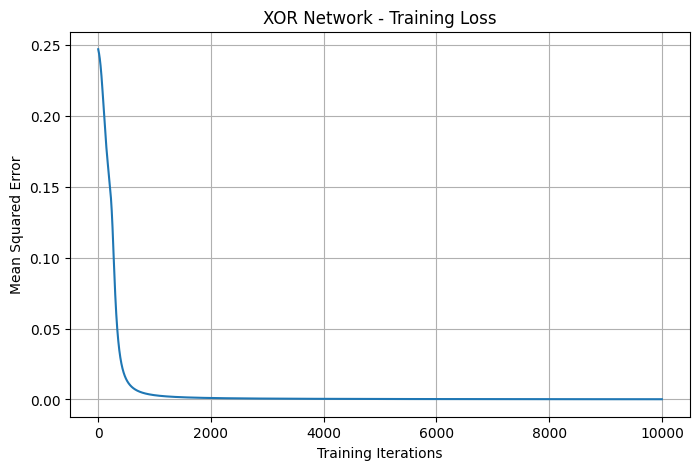

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(loss_history)

plt.xlabel("Training Iterations")
plt.ylabel("Mean Squared Error")
plt.title("XOR Network - Training Loss")
plt.grid(True)

plt.show()

### How Backpropagation Works

1. The neural network first makes a prediction using forward propagation.
2. The loss function calculates the difference between the predicted output and the actual output.
3. Backpropagation calculates how much each weight and bias contributes to the error.
4. Gradient descent uses these gradients to update the weights and biases.
5. This process repeats many times until the network reduces its error and makes better predictions.